In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import shutil
from pathlib import Path

In [10]:
# Optional dashboard libraries are not installed automatically because support depends on the Python version.
# The report cells below use them when available and otherwise skip gracefully.
# %pip install ydata-profiling sweetviz dtale

# Task 1

In [6]:
taxis = sns.load_dataset('taxis')
taxi_sample = taxis.sample(min(3000, len(taxis)), random_state=42)
print(taxi_sample.shape)

try:
    from ydata_profiling import ProfileReport
except ImportError:
    print('ydata-profiling is unavailable; saving a basic HTML summary instead.')
    taxi_sample.describe(include='all').to_html('taxi_profile.html')
else:
    profile = ProfileReport(taxi_sample, title='Taxi Trips Profile')
    profile.to_file('taxi_profile.html')

(3000, 14)
ydata-profiling is unavailable; saving a basic HTML summary instead.


# Task 2

In [7]:
try:
    import sweetviz as sv
except ImportError:
    print('Sweetviz is unavailable; skipping the Sweetviz report.')
else:
    report = sv.compare_intra(taxi_sample, taxi_sample['payment'] == 'cash', ['Cash', 'Other'], target_feat='fare')
    report.show_html(filepath='taxi_sweetviz_cash_vs_other.html', open_browser=False)

Sweetviz is unavailable; skipping the Sweetviz report.


# Task 3

In [8]:
try:
    import dtale
except ImportError:
    print('D-Tale is unavailable; skipping the interactive dashboard.')
else:
    d = dtale.show(taxi_sample)
    print('Open this D-Tale URL in a browser:', d.main_url())

D-Tale is unavailable; skipping the interactive dashboard.


# Task 4

Strongest pair: ('distance', 'fare') correlation: 0.919


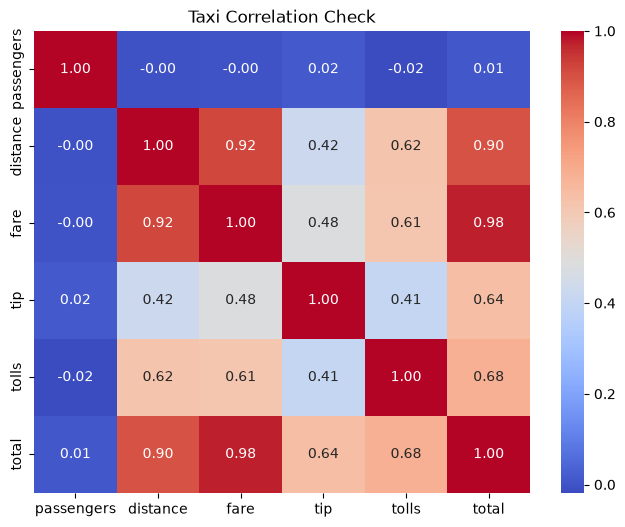

In [9]:
corr = taxi_sample.corr(numeric_only=True)

cols = [c for c in corr.columns if c != 'total']
sub = corr.loc[cols, cols].abs()
sub = sub.where(~np.eye(len(cols), dtype=bool))

pairs = sub.stack()
top_pair = pairs.idxmax()
print("Strongest pair:", top_pair, "correlation:", round(corr.loc[top_pair[0], top_pair[1]], 3))

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Taxi Correlation Check')
fig.savefig('taxi_corr_check.png')
plt.show()